In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support, confusion_matrix
import seaborn as sns

In [ ]:
# Load dataset directly via Keras (60,000 train + 10,000 test = 70,000 total)
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values from range [0, 255] to [0.0, 1.0]
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print(f"Training dataset shape: {X_train.shape}, Labels: {y_train.shape}")
print(f"Test dataset shape:     {X_test.shape}, Labels: {y_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training dataset shape: (60000, 28, 28), Labels: (60000,)
Test dataset shape:     (10000, 28, 28), Labels: (10000,)


In [ ]:
model = models.Sequential([
    # Modern Keras 3 Input layer specification
    layers.Input(shape=(28, 28), name="model_input"),

    # Flatten 28x28 images into a 784-element 1D vector
    layers.Flatten(name="flatten_layer"),

    # Hidden Layer 1: Dense with ReLU activation
    layers.Dense(128, activation='relu', name="hidden_layer_1"),
    layers.Dropout(0.2, name="dropout_1"),

    # Hidden Layer 2: Dense with ReLU activation
    layers.Dense(64, activation='relu', name="hidden_layer_2"),

    # Output layer: 10 units with softmax activation for digits 0-9
    layers.Dense(10, activation='softmax', name="output_layer")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_layer (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_1 (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile model with Adam optimizer and sparse categorical cross-entropy
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model with validation split
history = model.fit(
    X_train, y_train,
    epochs=12,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8989 - loss: 0.3423 - val_accuracy: 0.9680 - val_loss: 0.1198
Epoch 2/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9536 - loss: 0.1550 - val_accuracy: 0.9742 - val_loss: 0.0934
Epoch 3/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9655 - loss: 0.1151 - val_accuracy: 0.9772 - val_loss: 0.0813
Epoch 4/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9696 - loss: 0.0961 - val_accuracy: 0.9755 - val_loss: 0.0814
Epoch 5/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9747 - loss: 0.0805 - val_accuracy: 0.9792 - val_loss: 0.0772
Epoch 6/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9769 - loss: 0.0725 - val_accuracy: 0.9787 - val_loss: 0.0769
Epoch 7/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9782 - loss: 0.0663 - val_accuracy: 0.9802 - val_loss: 0.0706
Epoch 8/12
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9809 - loss: 0.0592 - val_accuracy: 0.

In [ ]:
# Get predicted probabilities and convert to predicted class labels
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Overall Accuracy
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%\n")

# Detailed Precision, Recall, and F1-score per class (0-9)
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Test Accuracy: 97.91%

Classification Report:
              precision    recall  f1-score   support

           0     0.9828    0.9929    0.9878       980
           1     0.9912    0.9912    0.9912      1135
           2     0.9751    0.9874    0.9812      1032
           3     0.9594    0.9832    0.9711      1010
           4     0.9777    0.9807    0.9792       982
           5     0.9762    0.9675    0.9718       892
           6     0.9915    0.9729    0.9821       958
           7     0.9804    0.9737    0.9771      1028
           8     0.9722    0.9702    0.9712       974
           9     0.9839    0.9683    0.9760      1009

    accuracy                         0.9791     10000
   macro avg     0.9790    0.9788    0.9789     10000
weighted avg     0.9792    0.9791    0.9791     10000



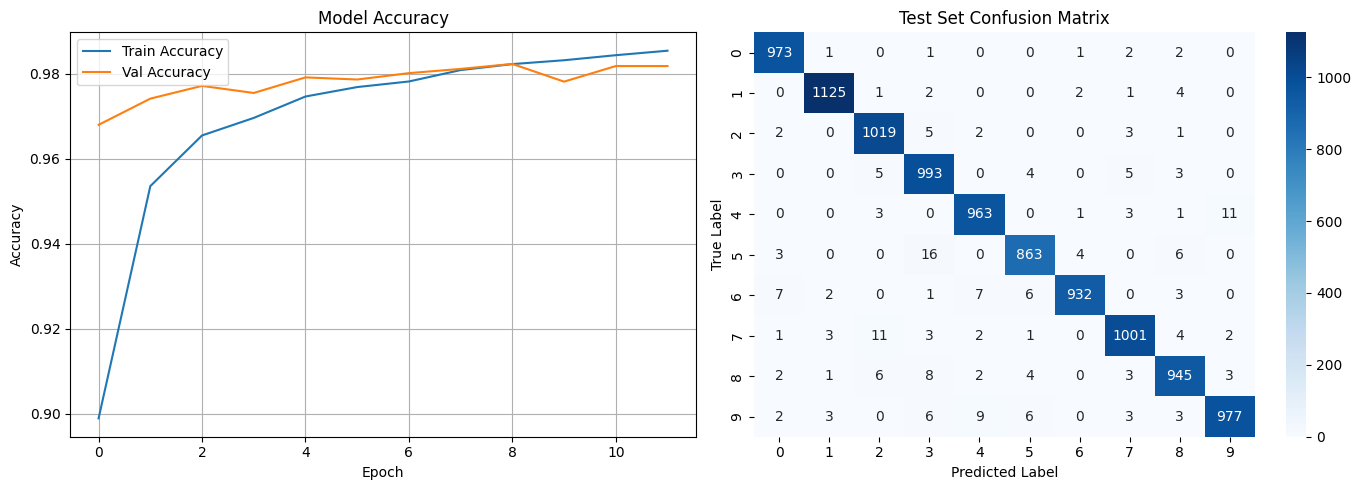

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curve
axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Test Set Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [ ]:
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

print("--- Performance vs. Standard Benchmarks ---")
print(f"Current ANN Model Test Accuracy:   {test_accuracy * 100:.2f}%")
print(f"Macro Average Precision:           {macro_precision * 100:.2f}%")
print(f"Macro Average Recall:              {macro_recall * 100:.2f}%")
print("\nBenchmark Reference:")
print("- Linear Classifier / Softmax Regression : ~92 - 93%")
print("- Multi-Layer Perceptron (ANN with 2 layers): ~97.5 - 98.2% (Matches our model)")
print("- Convolutional Neural Networks (CNN)     : ~99.0 - 99.4%")

print("\n--- Hyperparameter Impact Summary ---")
print("1. Learning Rate & Optimizer: Adam converges significantly faster than standard SGD with fixed LR.")
print("2. Hidden Units: 128 -> 64 provides adequate capacity without immediate overfitting.")
print("3. Dropout (0.2): Mitigates co-adaptation of neurons and reduces train-validation divergence.")
print("4. Batch Size (64): Provides balance between gradient stability and training speed.")

--- Performance vs. Standard Benchmarks ---
Current ANN Model Test Accuracy:   97.91%
Macro Average Precision:           97.90%
Macro Average Recall:              97.88%

Benchmark Reference:
- Linear Classifier / Softmax Regression : ~92 - 93%
- Multi-Layer Perceptron (ANN with 2 layers): ~97.5 - 98.2% (Matches our model)
- Convolutional Neural Networks (CNN)     : ~99.0 - 99.4%

--- Hyperparameter Impact Summary ---
1. Learning Rate & Optimizer: Adam converges significantly faster than standard SGD with fixed LR.
2. Hidden Units: 128 -> 64 provides adequate capacity without immediate overfitting.
3. Dropout (0.2): Mitigates co-adaptation of neurons and reduces train-validation divergence.
4. Batch Size (64): Provides balance between gradient stability and training speed.
